K-nearest neighbours has no training step and no parameters. It stores the data, and
when asked to classify a point it looks at the $k$ closest stored examples and takes a
vote.

That sounds too simple to be interesting, but three real ideas hide inside it:

1. **What "closest" means** &mdash; the distance metric, and why unscaled features silently
   break it,
2. **What $k$ controls** &mdash; a direct, visible bias/variance dial,
3. **Why it fails in high dimensions** &mdash; the curse of dimensionality, which is easiest
   to demonstrate here.

Everything below computes the distance matrix explicitly, votes by hand, and checks the
result against scikit-learn.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
np.set_printoptions(precision=4, suppress=True, linewidth=140)


def banner(title, ch="="):
    print(ch * 78)
    print(f"  {title}")
    print(ch * 78)


def step(label):
    print()
    print(label)
    print("=" * 78)


def check(manual, from_array, label="MATCH"):
    ok = np.allclose(manual, from_array)
    print(f"      = {manual:+.6f}   |  from array: {from_array:+.6f}   |  {label}: {ok}")
    return ok


def expand(u, v, per_line=4):
    """Write a dot product out term by term."""
    terms = [f"({a:+.4f})*({b:+.4f})" for a, b in zip(u, v)]
    lines, out = [], ""
    for i, t in enumerate(terms):
        out += t + (" + " if i < len(terms) - 1 else "")
        if (i + 1) % per_line == 0:
            lines.append(out); out = ""
    if out:
        lines.append(out)
    return "\n      ".join(lines)


def show_matrix(M, name="M", rows=None, cols=None, fmt="{:+8.3f}", max_cols=14):
    M = np.asarray(M)
    if M.ndim == 1:
        M = M[None, :]
    cut = M.shape[1] > max_cols
    Ms = M[:, :max_cols] if cut else M
    print(f"{name} {np.asarray(M).shape}" +
          (f"   [first {max_cols} of {M.shape[1]} columns]" if cut else "") + " =")
    if cols is not None:
        head = "".join(f"{str(c):>10}" for c in (cols[:max_cols] if cut else cols))
        print(" " * 13 + head)
    for r in range(Ms.shape[0]):
        lab = f"{str(rows[r]):>10} | " if rows is not None else f"{r:>10} | "
        print("   " + lab + "  ".join(fmt.format(v) for v in Ms[r]))


def show_matmul(A, B, C, na="A", nb="B", nc="C", i=0, j=0,
                rows_A=None, note=None, max_cols=14):
    """Print both operands of A @ B = C, then verify one element by hand."""
    A, B, C = np.asarray(A), np.asarray(B), np.asarray(C)
    banner(f"{na} {A.shape}   @   {nb} {B.shape}   =   {nc} {C.shape}")
    print(f"  shape rule: ({A.shape[0]} x {A.shape[1]}) @ ({B.shape[0]} x {B.shape[1]})"
          f" -> ({A.shape[0]} x {B.shape[1]})   inner dim {A.shape[1]} cancels")
    if note:
        print(f"  {note}")
    print("=" * 78)
    print()
    show_matrix(A, na, rows_A, max_cols=max_cols)
    print()
    show_matrix(B, nb, max_cols=max_cols)
    print()
    show_matrix(C, nc, rows_A, max_cols=max_cols)
    print(f"\n  worked element  {nc}[{i},{j}]  =  row {i} of {na}  .  column {j} of {nb}")
    print(f"      row {i} of {na} = {np.round(A[i], 4)}")
    print(f"      col {j} of {nb} = {np.round(B[:, j], 4)}")
    print(f"      {expand(A[i], B[:, j])}")
    check(float(A[i] @ B[:, j]), float(C[i, j]))


def show_elementwise(A, B, C, na, nb, nc, op="+", rows=None):
    A, B, C = np.asarray(A), np.asarray(B), np.asarray(C)
    banner(f"{nc} = {na} {op} {nb}      all three are {A.shape} - element-wise")
    for r in range(A.shape[0]):
        lab = f"{rows[r]:>10}" if rows is not None else f"{r:>10}"
        print(f"\n{lab} |")
        print("   " + f"{na:>14}: " + "  ".join(f"{v:+8.3f}" for v in A[r]))
        print("   " + f"{nb:>14}: " + "  ".join(f"{v:+8.3f}" for v in B[r]))
        print("   " + f"{nc:>14}: " + "  ".join(f"{v:+8.3f}" for v in C[r]))
    print(f"\n  check [0,0]: {A[0,0]:+.6f} {op} {B[0,0]:+.6f} = {C[0,0]:+.6f}   "
          f"MATCH: {np.isclose(A[0,0] + B[0,0] if op == '+' else A[0,0] - B[0,0], C[0,0])}")


print("Display helpers ready: banner, step, check, expand, show_matrix, "
      "show_matmul, show_elementwise.")

Display helpers ready: banner, step, check, expand, show_matrix, show_matmul, show_elementwise.


---
# 1. The Data

The same 20 EEG epochs used in the Logistic Regression walkthrough, so the decision
boundaries can be compared side by side.

Look carefully at the two feature ranges printed below &mdash; that gap is about to matter
more than anything else in this notebook.

In [2]:
# ----------------------------------------------------------------------------
#  20 EEG epochs, two features, two classes. Small enough to print in full,
#  and deliberately NOT perfectly separable.
# ----------------------------------------------------------------------------
feat2 = ["spike_rate", "line_length"]

P = np.array([
    [1.0, 12.0], [1.6, 15.0], [0.7, 11.0], [2.1, 18.0], [1.3, 14.0],
    [2.6, 21.0], [0.9, 16.0], [1.9, 13.0], [3.1, 24.0], [2.3, 17.0],
    [6.2, 41.0], [7.1, 47.0], [5.4, 38.0], [8.0, 52.0], [6.7, 44.0],
    [5.9, 49.0], [7.6, 39.0], [6.0, 35.0], [4.7, 43.0], [8.3, 46.0],
])
t2 = np.array([0]*10 + [1]*10)

# two deliberate overlaps, so no straight line separates the data perfectly
P[9]  = [4.4, 33.0]      # a class-0 epoch pushed into class-1 territory
t2[9] = 0
P[18] = [3.6, 27.0]      # a class-1 epoch pushed down toward class 0
t2[18] = 1

n2 = len(P)
ep_ids = [f"ep{i:02d}" for i in range(n2)]
cls_names = ["no seizure", "seizure"]

print(f"{n2} epochs x {P.shape[1]} features, classes {np.bincount(t2).tolist()}\n")
hdr = f"{'id':>6}  {feat2[0]:>11}  {feat2[1]:>12}  {'class':>6}  {'label':>12}"
print(hdr); print("-" * len(hdr))
for i in range(n2):
    print(f"{ep_ids[i]:>6}  {P[i,0]:>11.1f}  {P[i,1]:>12.1f}  {t2[i]:>6}  "
          f"{cls_names[t2[i]]:>12}")
print("-" * len(hdr))
print(f"\nfeature means : {np.round(P.mean(axis=0), 3)}")
print(f"feature stds  : {np.round(P.std(axis=0), 3)}")
print(f"\nNote the scales: {feat2[1]} spans ~{P[:,1].ptp() if hasattr(P[:,1],'ptp') else np.ptp(P[:,1]):.0f} "
      f"while {feat2[0]} spans ~{np.ptp(P[:,0]):.0f}.")
print("Any algorithm that measures DISTANCE will be dominated by the larger one")
print("unless the features are scaled - that matters for KNN and SVM below.")

20 epochs x 2 features, classes [10, 10]

    id   spike_rate   line_length   class         label
-------------------------------------------------------
  ep00          1.0          12.0       0    no seizure
  ep01          1.6          15.0       0    no seizure
  ep02          0.7          11.0       0    no seizure
  ep03          2.1          18.0       0    no seizure
  ep04          1.3          14.0       0    no seizure
  ep05          2.6          21.0       0    no seizure
  ep06          0.9          16.0       0    no seizure
  ep07          1.9          13.0       0    no seizure
  ep08          3.1          24.0       0    no seizure
  ep09          4.4          33.0       0    no seizure
  ep10          6.2          41.0       1       seizure
  ep11          7.1          47.0       1       seizure
  ep12          5.4          38.0       1       seizure
  ep13          8.0          52.0       1       seizure
  ep14          6.7          44.0       1       seizure
  ep15

---
# 2. Distance

The default is Euclidean distance:

$$d(\mathbf{a},\mathbf{b}) = \sqrt{\sum_j (a_j - b_j)^2}$$

Other choices change the shape of a "neighbourhood":

$$\text{Manhattan: } \sum_j |a_j - b_j|
\qquad
\text{Minkowski}_p: \Big(\sum_j |a_j-b_j|^p\Big)^{1/p}
\qquad
\text{Chebyshev: } \max_j |a_j - b_j|$$

Euclidean and Manhattan are Minkowski with $p = 2$ and $p = 1$.

In [3]:
def euclid(a, b):
    return float(np.sqrt(np.sum((a - b) ** 2)))

query = np.array([4.0, 30.0])       # a new epoch to classify
print(f"a new epoch to classify: {feat2[0]} = {query[0]}, {feat2[1]} = {query[1]}\n")

i = 0
d0 = euclid(query, P[i])
print(f"distance to {ep_ids[i]} = {P[i]}, worked out:")
print(f"   d^2 = ({query[0]:.1f} - {P[i,0]:.1f})^2 + ({query[1]:.1f} - {P[i,1]:.1f})^2")
print(f"       = ({query[0]-P[i,0]:+.1f})^2 + ({query[1]-P[i,1]:+.1f})^2")
print(f"       = {(query[0]-P[i,0])**2:.2f} + {(query[1]-P[i,1])**2:.2f} = "
      f"{(query[0]-P[i,0])**2 + (query[1]-P[i,1])**2:.2f}")
print(f"   d   = sqrt({(query[0]-P[i,0])**2 + (query[1]-P[i,1])**2:.2f}) = {d0:.6f}")
print(f"\n   NOTICE: {(query[1]-P[i,1])**2:.0f} of the {(query[0]-P[i,0])**2 + (query[1]-P[i,1])**2:.0f} "
      f"comes from {feat2[1]} alone.")
print(f"   {feat2[0]} contributed {(query[0]-P[i,0])**2:.2f} - essentially nothing.")

d_raw = np.array([euclid(query, P[i]) for i in range(n2)])
order_raw = np.argsort(d_raw)

print(f"\n\nall {n2} distances from the query, sorted\n")
print(f"{'rank':>5}  {'id':>6}  {feat2[0]:>11}  {feat2[1]:>12}  {'distance':>10}  {'class':>6}")
print("-" * 60)
for r, i in enumerate(order_raw, 1):
    print(f"{r:>5}  {ep_ids[i]:>6}  {P[i,0]:>11.1f}  {P[i,1]:>12.1f}  {d_raw[i]:>10.4f}  "
          f"{t2[i]:>6}")
print("-" * 60)

a new epoch to classify: spike_rate = 4.0, line_length = 30.0

distance to ep00 = [ 1. 12.], worked out:
   d^2 = (4.0 - 1.0)^2 + (30.0 - 12.0)^2
       = (+3.0)^2 + (+18.0)^2
       = 9.00 + 324.00 = 333.00
   d   = sqrt(333.00) = 18.248288

   NOTICE: 324 of the 333 comes from line_length alone.
   spike_rate contributed 9.00 - essentially nothing.


all 20 distances from the query, sorted

 rank      id   spike_rate   line_length    distance   class
------------------------------------------------------------
    1    ep09          4.4          33.0      3.0265       0
    2    ep18          3.6          27.0      3.0265       1
    3    ep17          6.0          35.0      5.3852       1
    4    ep08          3.1          24.0      6.0671       0
    5    ep12          5.4          38.0      8.1216       1
    6    ep05          2.6          21.0      9.1082       0
    7    ep16          7.6          39.0      9.6933       1
    8    ep10          6.2          41.0     11.2178   

### Scaling is not optional

`line_length` spans roughly 40 units; `spike_rate` spans roughly 7. Squared, that is a
factor of about 30. So Euclidean distance is **almost entirely** a measure of
`line_length`, and `spike_rate` is effectively ignored &mdash; not because it is
uninformative, but because it is measured in smaller numbers.

Standardising each feature to zero mean and unit variance puts them on equal terms:

$$z_j = \frac{x_j - \mu_j}{\sigma_j}$$

In [4]:
mu, sd = P.mean(axis=0), P.std(axis=0)
Pz = (P - mu) / sd
qz = (query - mu) / sd

print(f"feature   {'mean':>10}  {'std':>10}")
print("-" * 34)
for j, f in enumerate(feat2):
    print(f"{f:>9}  {mu[j]:>10.4f}  {sd[j]:>10.4f}")
print("-" * 34)
print(f"\nquery raw        : {query}")
print(f"query standardised: {np.round(qz, 4)}\n")

d_z = np.array([euclid(qz, Pz[i]) for i in range(n2)])
order_z = np.argsort(d_z)

print("how much each feature contributes to the squared distance, on average\n")
raw_contrib = np.array([((query - P[i])**2) for i in range(n2)]).mean(axis=0)
z_contrib = np.array([((qz - Pz[i])**2) for i in range(n2)]).mean(axis=0)
print(f"{'feature':>12}  {'raw share':>12}  {'scaled share':>14}")
print("-" * 42)
for j, f in enumerate(feat2):
    print(f"{f:>12}  {raw_contrib[j]/raw_contrib.sum():>11.1%}  "
          f"{z_contrib[j]/z_contrib.sum():>13.1%}")
print("-" * 42)

print(f"\n\nthe 5 nearest neighbours change completely:\n")
print(f"{'rank':>5}  {'raw distance':>22}  {'scaled distance':>22}")
print("-" * 54)
for r in range(5):
    a, b = order_raw[r], order_z[r]
    print(f"{r+1:>5}  {ep_ids[a] + f' (d={d_raw[a]:.3f}, c={t2[a]})':>22}  "
          f"{ep_ids[b] + f' (d={d_z[b]:.3f}, c={t2[b]})':>22}")
print("-" * 54)
same = set(order_raw[:5].tolist()) == set(order_z[:5].tolist())
print(f"\nsame 5 neighbours either way? {same}")

feature         mean         std
----------------------------------
spike_rate      4.2200      2.5637
line_length     29.7500     13.7945
----------------------------------

query raw        : [ 4. 30.]
query standardised: [-0.0858  0.0181]

how much each feature contributes to the squared distance, on average

     feature     raw share    scaled share
------------------------------------------
  spike_rate         3.4%          50.2%
 line_length        96.6%          49.8%
------------------------------------------


the 5 nearest neighbours change completely:

 rank            raw distance         scaled distance
------------------------------------------------------
    1     ep09 (d=3.027, c=0)     ep18 (d=0.268, c=1)
    2     ep18 (d=3.027, c=1)     ep09 (d=0.268, c=0)
    3     ep17 (d=5.385, c=1)     ep08 (d=0.559, c=0)
    4     ep08 (d=6.067, c=0)     ep12 (d=0.797, c=1)
    5     ep12 (d=8.122, c=1)     ep05 (d=0.851, c=0)
-------------------------------------------------

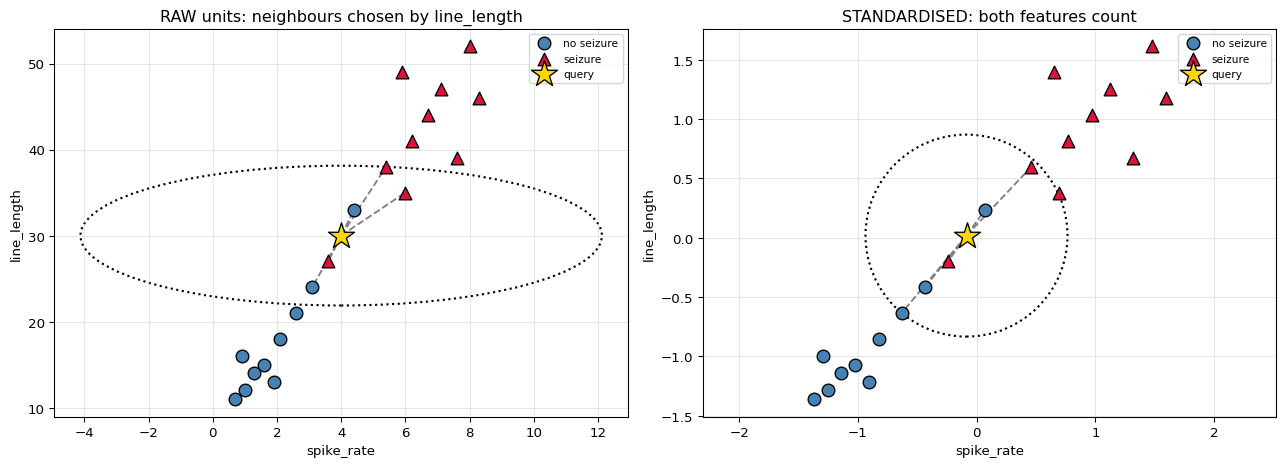

The dotted circle is the k = 5 neighbourhood. On the left it is stretched by
the axis scales into something that only measures line_length; on the right
it is a genuine circle in a space where both features carry equal weight.


In [5]:
def plot2d(ax=None, scaled=False, title="", legend=True):
    A = Pz if scaled else P
    own = ax is None
    if own:
        fig, ax = plt.subplots(figsize=(7, 5))
    for c, (col, mk) in enumerate([("steelblue", "o"), ("crimson", "^")]):
        m = t2 == c
        ax.scatter(A[m, 0], A[m, 1], c=col, marker=mk, s=90, edgecolor="k",
                   label=cls_names[c], zorder=3)
    ax.set(xlabel=feat2[0] + (" (scaled)" if scaled else ""),
           ylabel=feat2[1] + (" (scaled)" if scaled else ""), title=title)
    if legend:
        ax.legend(fontsize=8)
    ax.grid(alpha=.3)
    return ax

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5))

K = 5
for ax, A, q, dd, oo, ttl in [
        (axes[0], P, query, d_raw, order_raw, "RAW units: neighbours chosen by line_length"),
        (axes[1], Pz, qz, d_z, order_z, "STANDARDISED: both features count")]:
    for c, (col, mk) in enumerate([("steelblue", "o"), ("crimson", "^")]):
        m = t2 == c
        ax.scatter(A[m, 0], A[m, 1], c=col, marker=mk, s=90, edgecolor="k",
                   label=cls_names[c], zorder=3)
    ax.scatter([q[0]], [q[1]], marker="*", s=420, color="gold", edgecolor="k",
               zorder=5, label="query")
    for i in oo[:K]:
        ax.plot([q[0], A[i, 0]], [q[1], A[i, 1]], color="grey", lw=1.4,
                ls="--", zorder=2)
    circ = plt.Circle((q[0], q[1]), dd[oo[K-1]], fill=False, color="k",
                      lw=1.6, ls=":")
    ax.add_patch(circ)
    ax.set(xlabel=feat2[0], ylabel=feat2[1], title=ttl)
    ax.legend(fontsize=8); ax.grid(alpha=.3)
axes[1].set_aspect("equal", adjustable="datalim")
plt.tight_layout(); plt.show()

print("The dotted circle is the k = 5 neighbourhood. On the left it is stretched by")
print("the axis scales into something that only measures line_length; on the right")
print("it is a genuine circle in a space where both features carry equal weight.")

---
# 3. The Vote

$$\hat{y} = \arg\max_{c} \sum_{i \in N_k(\mathbf{x})} \mathbb{1}[\,y_i = c\,]$$

with $N_k$ the $k$ nearest stored points. Distance-weighted voting instead gives each
neighbour a say proportional to $1/d$, so a very close neighbour outweighs a marginal
one:

$$\hat{y} = \arg\max_{c} \sum_{i \in N_k} \frac{1}{d_i}\,\mathbb{1}[\,y_i = c\,]$$

In [6]:
print(f"query standardised = {np.round(qz, 4)}\n")
for K in (1, 3, 5, 7, 9):
    nb = order_z[:K]
    votes = np.bincount(t2[nb], minlength=2)
    winner = int(np.argmax(votes))
    wts = 1.0 / np.maximum(d_z[nb], 1e-12)
    wv = np.array([wts[t2[nb] == c].sum() for c in (0, 1)])
    wwin = int(np.argmax(wv))
    print(f"k = {K}:")
    print(f"   neighbours : " + ", ".join(f"{ep_ids[i]}(c{t2[i]},d={d_z[i]:.3f})" for i in nb))
    print(f"   plain vote : class0 {votes[0]}, class1 {votes[1]}  ->  predict {winner}")
    print(f"   weighted   : class0 {wv[0]:.4f}, class1 {wv[1]:.4f}  ->  predict {wwin}")
    print()

K = 5
nb = order_z[:K]
print(f"the k = {K} weighted vote, written out:\n")
for c in (0, 1):
    members = [i for i in nb if t2[i] == c]
    if not members:
        print(f"   class {c}: no neighbours -> weight 0")
        continue
    terms = " + ".join(f"1/{d_z[i]:.4f}" for i in members)
    tot = sum(1/d_z[i] for i in members)
    print(f"   class {c}: {terms} = {tot:.6f}")
print(f"\n   -> predict class {int(np.argmax([sum(1/d_z[i] for i in nb if t2[i]==c) for c in (0,1)]))}")

query standardised = [-0.0858  0.0181]

k = 1:
   neighbours : ep18(c1,d=0.268)
   plain vote : class0 0, class1 1  ->  predict 1
   weighted   : class0 0.0000, class1 3.7361  ->  predict 1

k = 3:
   neighbours : ep18(c1,d=0.268), ep09(c0,d=0.268), ep08(c0,d=0.559)
   plain vote : class0 2, class1 1  ->  predict 0
   weighted   : class0 5.5252, class1 3.7361  ->  predict 0

k = 5:
   neighbours : ep18(c1,d=0.268), ep09(c0,d=0.268), ep08(c0,d=0.559), ep12(c1,d=0.797), ep05(c0,d=0.851)
   plain vote : class0 3, class1 2  ->  predict 0
   weighted   : class0 6.7005, class1 4.9915  ->  predict 0

k = 7:
   neighbours : ep18(c1,d=0.268), ep09(c0,d=0.268), ep08(c0,d=0.559), ep12(c1,d=0.797), ep05(c0,d=0.851), ep17(c1,d=0.860), ep03(c0,d=1.143)
   plain vote : class0 4, class1 3  ->  predict 0
   weighted   : class0 7.5756, class1 6.1540  ->  predict 0

k = 9:
   neighbours : ep18(c1,d=0.268), ep09(c0,d=0.268), ep08(c0,d=0.559), ep12(c1,d=0.797), ep05(c0,d=0.851), ep17(c1,d=0.860), ep03(c0,d

---
# 4. What $k$ Controls

$k$ is a bias/variance dial, and unusually for machine learning you can *see* it:

* $k = 1$ &mdash; every training point gets its own island. Zero training error, maximum
  variance, and a boundary that contorts around individual noisy points.
* $k = n$ &mdash; every query gets the same answer, the majority class. Zero variance,
  maximum bias.

The interesting values are in between. Note that $k=1$ scoring 100% on training data is
meaningless: the nearest neighbour of a training point **is itself**, at distance zero.

In [7]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import LeaveOneOut, cross_val_score

def knn_predict(A, labels, q, K, weighted=False):
    d = np.sqrt(((A - q) ** 2).sum(axis=1))
    idx = np.argsort(d)[:K]
    if weighted:
        wts = 1.0 / np.maximum(d[idx], 1e-12)
        return int(np.argmax([wts[labels[idx] == c].sum() for c in (0, 1)]))
    return int(np.argmax(np.bincount(labels[idx], minlength=2)))

ks = [1, 3, 5, 7, 9, 11, 15, 19]
print(f"{'k':>4}  {'train acc':>10}  {'LOO-CV acc':>11}  {'note':>34}")
print("-" * 64)
loo_scores = []
for K in ks:
    tr = np.mean([knn_predict(Pz, t2, Pz[i], K) == t2[i] for i in range(n2)])
    cv = cross_val_score(KNeighborsClassifier(n_neighbors=K), Pz, t2,
                         cv=LeaveOneOut()).mean()
    loo_scores.append(cv)
    note = ""
    if K == 1:
        note = "each point is its own neighbour"
    elif K >= n2 - 1:
        note = "approaching majority-class"
    print(f"{K:>4}  {tr:>10.4f}  {cv:>11.4f}  {note:>34}")
print("-" * 64)
best_k = ks[int(np.argmax(loo_scores))]
print(f"\nbest k by leave-one-out CV: {best_k}  (accuracy {max(loo_scores):.4f})")
print("\nTraining accuracy is 1.0 at k=1 and tells us nothing. Leave-one-out")
print("excludes the point itself, which is the only honest measure on 20 samples.")

   k   train acc   LOO-CV acc                                note
----------------------------------------------------------------
   1      1.0000       0.9000     each point is its own neighbour
   3      0.9000       0.9000                                    
   5      0.9000       0.9000                                    
   7      0.9000       0.9000                                    
   9      0.9000       0.9000                                    
  11      0.9000       0.9000                                    
  15      0.9000       0.9000                                    
  19      0.9000       0.0000          approaching majority-class
----------------------------------------------------------------

best k by leave-one-out CV: 1  (accuracy 0.9000)

Training accuracy is 1.0 at k=1 and tells us nothing. Leave-one-out
excludes the point itself, which is the only honest measure on 20 samples.


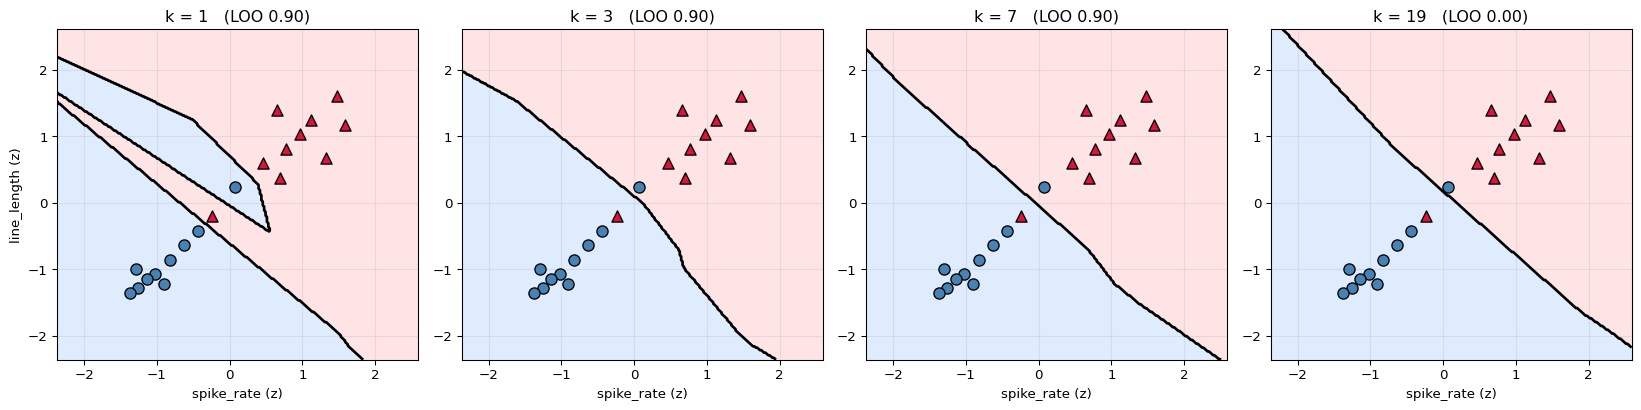

k = 1 carves separate pockets around the two awkward epochs - that is
variance. k = 19 has washed the boundary away entirely - that is bias.


In [8]:
gx, gy = np.meshgrid(np.linspace(Pz[:,0].min()-1, Pz[:,0].max()+1, 260),
                     np.linspace(Pz[:,1].min()-1, Pz[:,1].max()+1, 260))
G = np.column_stack([gx.ravel(), gy.ravel()])

show_ks = [1, 3, 7, 19]
fig, axes = plt.subplots(1, len(show_ks), figsize=(4.3*len(show_ks), 4.4))
for ax, K in zip(axes, show_ks):
    m = KNeighborsClassifier(n_neighbors=K).fit(Pz, t2)
    zz = m.predict(G).reshape(gx.shape)
    ax.contourf(gx, gy, zz, levels=[-.5,.5,1.5], colors=["#dbeafe","#fee2e2"], alpha=.9)
    ax.contour(gx, gy, zz, levels=[.5], colors="k", linewidths=2)
    for c, (col, mk) in enumerate([("steelblue","o"), ("crimson","^")]):
        mm = t2 == c
        ax.scatter(Pz[mm,0], Pz[mm,1], c=col, marker=mk, s=70, edgecolor="k", zorder=3)
    ax.set(title=f"k = {K}   (LOO {loo_scores[ks.index(K)]:.2f})",
           xlabel=feat2[0]+" (z)")
    if K == show_ks[0]:
        ax.set_ylabel(feat2[1]+" (z)")
    ax.grid(alpha=.25)
plt.tight_layout(); plt.show()

print("k = 1 carves separate pockets around the two awkward epochs - that is")
print("variance. k = 19 has washed the boundary away entirely - that is bias.")

---
# 5. The Curse of Dimensionality

KNN rests on one assumption: **near points have similar labels**. In high dimensions
that assumption quietly dies, because *everything becomes equally far away*.

For $n$ points spread in $d$ dimensions, the contrast between the nearest and farthest
neighbour shrinks as $d$ grows:

$$\frac{d_{\max} - d_{\min}}{d_{\min}} \;\longrightarrow\; 0 \qquad \text{as } d \to \infty$$

Once that ratio approaches zero, "nearest" carries almost no information &mdash; the vote is
close to random. This is the single most important limitation of the method, and it is
easy to demonstrate.

500 uniform random points; distance from one query point

  dims      d_min      d_max       mean   (max-min)/min   std/mean
------------------------------------------------------------------
     1     0.0015     0.9159     0.4549        615.8064     0.6143
     2     0.0139     1.1548     0.6159         82.0189     0.4169
     3     0.0729     1.2504     0.6322         16.1509     0.3628
     5     0.2176     1.5075     0.8480          5.9276     0.2628
    10     0.6333     2.0570     1.3320          2.2480     0.1784
    25     1.5744     2.8810     2.2027          0.8299     0.1123
    50     2.2781     3.6173     2.9739          0.5879     0.0820
   100     3.2305     4.7314     4.2135          0.4646     0.0545
   500     8.2717     9.8038     9.1649          0.1852     0.0244
  1000    12.0941    13.3555    12.7334          0.1043     0.0178
------------------------------------------------------------------

In 1-D the farthest point is 616x further than the nearest.
In 1000-D 

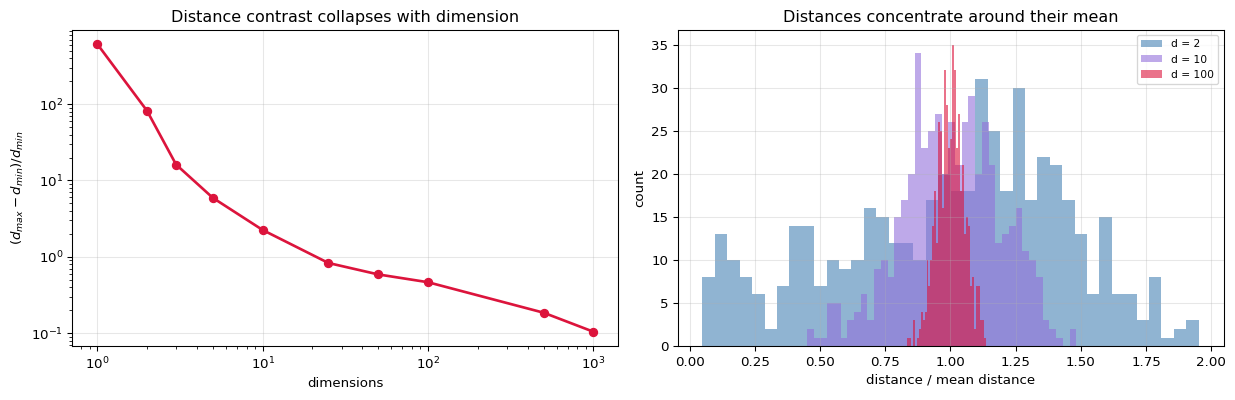


Right panel: at d = 100 every distance is within a few percent of the mean.
The practical consequence: KNN needs either few dimensions, or a
dimensionality-reduction step first (see the PCA walkthrough).


In [9]:
rng = np.random.default_rng(0)
N = 500

print(f"{N} uniform random points; distance from one query point\n")
print(f"{'dims':>6}  {'d_min':>9}  {'d_max':>9}  {'mean':>9}  "
      f"{'(max-min)/min':>14}  {'std/mean':>9}")
print("-" * 66)
dims = [1, 2, 3, 5, 10, 25, 50, 100, 500, 1000]
contrast = []
for d in dims:
    A = rng.random((N, d))
    q = rng.random(d)
    dist = np.sqrt(((A - q) ** 2).sum(axis=1))
    c = (dist.max() - dist.min()) / dist.min()
    contrast.append(c)
    print(f"{d:>6}  {dist.min():>9.4f}  {dist.max():>9.4f}  {dist.mean():>9.4f}  "
          f"{c:>14.4f}  {dist.std()/dist.mean():>9.4f}")
print("-" * 66)

print(f"\nIn 1-D the farthest point is {contrast[0]:.0f}x further than the nearest.")
print(f"In 1000-D it is only {contrast[-1]:.2f}x further - every point sits at")
print(f"almost exactly the same distance, so 'nearest' stops meaning anything.")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
axes[0].plot(dims, contrast, "o-", lw=2, color="crimson")
axes[0].set(xscale="log", yscale="log", xlabel="dimensions",
            ylabel=r"$(d_{max}-d_{min})/d_{min}$",
            title="Distance contrast collapses with dimension")
axes[0].grid(alpha=.3)

for d, col in [(2, "steelblue"), (10, "mediumpurple"), (100, "crimson")]:
    A = rng.random((N, d)); q = rng.random(d)
    dist = np.sqrt(((A - q) ** 2).sum(axis=1))
    axes[1].hist(dist / dist.mean(), bins=40, alpha=.6, label=f"d = {d}", color=col)
axes[1].set(xlabel="distance / mean distance", ylabel="count",
            title="Distances concentrate around their mean")
axes[1].legend(fontsize=8); axes[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

print("\nRight panel: at d = 100 every distance is within a few percent of the mean.")
print("The practical consequence: KNN needs either few dimensions, or a")
print("dimensionality-reduction step first (see the PCA walkthrough).")

---
# 6. Cost

There is no training cost at all &mdash; but every prediction rescans the dataset:

$$\text{train } O(1) \qquad\qquad \text{predict } O(n \cdot d) \text{ per query}$$

This is the opposite trade to every other model in this series, which pay up front and
predict cheaply. Tree-based indexes (KD-tree, ball-tree) reduce the query cost to roughly
$O(\log n)$ &mdash; but only in low dimensions. Above roughly 20 features they degrade to
brute force, for exactly the reason shown in the previous section.

In [10]:
import time
print(f"{'n':>8}  {'d':>5}  {'brute (ms)':>12}  {'kd_tree (ms)':>13}  {'winner':>10}")
print("-" * 56)
for n_, d_ in [(2000, 2), (2000, 20), (20000, 2), (20000, 20), (20000, 100)]:
    A = rng.random((n_, d_)); lab = rng.integers(0, 2, n_)
    Q = rng.random((200, d_))
    res = {}
    for algo in ("brute", "kd_tree"):
        m = KNeighborsClassifier(n_neighbors=5, algorithm=algo).fit(A, lab)
        t0 = time.perf_counter(); m.predict(Q); res[algo] = (time.perf_counter()-t0)*1000
    win = min(res, key=res.get)
    print(f"{n_:>8}  {d_:>5}  {res['brute']:>12.1f}  {res['kd_tree']:>13.1f}  {win:>10}")
print("-" * 56)
print("\nkd_tree wins comfortably in 2-D and loses its advantage as d grows -")
print("the same curse, showing up as a performance problem instead of an")
print("accuracy problem.")

       n      d    brute (ms)   kd_tree (ms)      winner
--------------------------------------------------------
    2000      2          13.9            2.2     kd_tree
    2000     20          15.2           19.2       brute
   20000      2          10.8            2.6     kd_tree
   20000     20           9.5          131.8       brute
   20000    100          15.1          679.9       brute
--------------------------------------------------------

kd_tree wins comfortably in 2-D and loses its advantage as d grows -
the same curse, showing up as a performance problem instead of an
accuracy problem.


---
# 7. Checking Against scikit-learn

In [11]:
for K in (1, 3, 5, 7):
    for weighted in (False, True):
        mine = np.array([knn_predict(Pz, t2, Pz[i], K, weighted) for i in range(n2)])
        sk = KNeighborsClassifier(n_neighbors=K,
                                  weights="distance" if weighted else "uniform").fit(Pz, t2)
        ok = np.array_equal(mine, sk.predict(Pz))
        print(f"k={K:>2}  weights={'distance' if weighted else 'uniform ':>8}  "
              f"MATCH: {ok}")

print()
K = 5
mine_q = knn_predict(Pz, t2, qz, K)
sk = KNeighborsClassifier(n_neighbors=K).fit(Pz, t2)
sk_q = int(sk.predict(qz[None, :])[0])
print(f"the query point, k = {K}:  ours {mine_q}, sklearn {sk_q}   "
      f"MATCH: {mine_q == sk_q}")

dist_sk, idx_sk = sk.kneighbors(qz[None, :])
print(f"\nneighbour indices ours    : {order_z[:K].tolist()}")
print(f"neighbour indices sklearn : {idx_sk[0].tolist()}")
print(f"MATCH: {set(order_z[:K].tolist()) == set(idx_sk[0].tolist())}")
print(f"\ndistances ours    : {np.round(np.sort(d_z)[:K], 6).tolist()}")
print(f"distances sklearn : {np.round(dist_sk[0], 6).tolist()}")
print(f"MATCH: {np.allclose(np.sort(d_z)[:K], dist_sk[0])}")

k= 1  weights=uniform   MATCH: True
k= 1  weights=distance  MATCH: True
k= 3  weights=uniform   MATCH: True
k= 3  weights=distance  MATCH: True
k= 5  weights=uniform   MATCH: True
k= 5  weights=distance  MATCH: True
k= 7  weights=uniform   MATCH: True
k= 7  weights=distance  MATCH: True

the query point, k = 5:  ours 0, sklearn 0   MATCH: True

neighbour indices ours    : [18, 9, 8, 12, 5]
neighbour indices sklearn : [18, 9, 8, 12, 5]
MATCH: True

distances ours    : [0.267657, 0.267657, 0.558951, 0.796581, 0.850811]
distances sklearn : [0.267657, 0.267657, 0.558951, 0.796581, 0.850811]
MATCH: True


---
# 8. Summary

| Property | KNN |
|---|---|
| Training | none &mdash; the data *is* the model |
| Prediction | $O(n\cdot d)$ per query |
| Distance | $\sqrt{\sum_j (a_j-b_j)^2}$ (or Manhattan, Minkowski, …) |
| Vote | majority, or weighted by $1/d$ |
| $k$ small | low bias, high variance, jagged boundary |
| $k$ large | high bias, low variance, smooth boundary |
| Requires scaling | **yes** &mdash; unscaled features silently dominate |
| High dimensions | fails: distances concentrate |

**The one idea:** KNN makes no assumption about the *shape* of the boundary, which is
its strength &mdash; it can represent anything. It assumes only that nearby points share
labels, which is its weakness, because "nearby" depends entirely on the units you happened
to measure in and collapses as dimensions grow.

**What is deliberately left out:** KD-tree and ball-tree construction, approximate
nearest neighbours (HNSW, LSH) which is what makes vector search practical at scale,
KNN regression (average instead of vote), learned metrics, and class-imbalance handling.